# Lab 5: Deret Waktu dan Data Panel

**Durasi:** 90 menit

Tujuan: menguji stasioneritas, meramal dengan ARIMA, menguji
kointegrasi, dan menaksir model data panel.



**Posisi dalam alur workshop.** Menambah dimensi waktu dan individu ke
model. Lab 6 menutup dengan data Indonesia asli.



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**. Paket `linearmodels` dipasang di sel berikutnya
(butuh internet sekali saja).



**Alur sesi:** kita menggunakan urutan waktu dan pengamatan berulang. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan data aktual, ramalan, dan pola antarunit.

Jalankan contoh terbimbing sampai hasilnya muncul, kemudian lengkapi sel latihan yang masih berupa komentar.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
%pip install "linearmodels==7.1" -q


Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## 1. Stasioneritas dan ARIMA

Data `data/ts_inflasi.csv`: indeks harga 50 periode yang naik terus.
Langkah pertama selalu melihat plot.



Nama kolom inflasi pada CSV simulasi ini menunjukkan seri indeks harga. Nilai levelnya bukan inflasi YoY dalam persen; pembedaan ini penting sebelum membaca hasil ADF dan ramalan.

<!-- kamus_variabel:ts_inflasi.csv -->

### Kenali data: Deret harga/inflasi simulasi

**Data:** `data/ts_inflasi.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `inflasi` | Deret level bertendensi naik, dicontohkan sebagai IHK pada sumber. | Level/indeks simulasi; bukan otomatis persen inflasi | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [4]:
inflasi = pd.read_csv(URL_DATA + "ts_inflasi.csv")

inflasi.head()

,obs,inflasi
0,1,100.5
1,2,101.2
2,3,101.8
3,4,102.5
4,5,103.1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

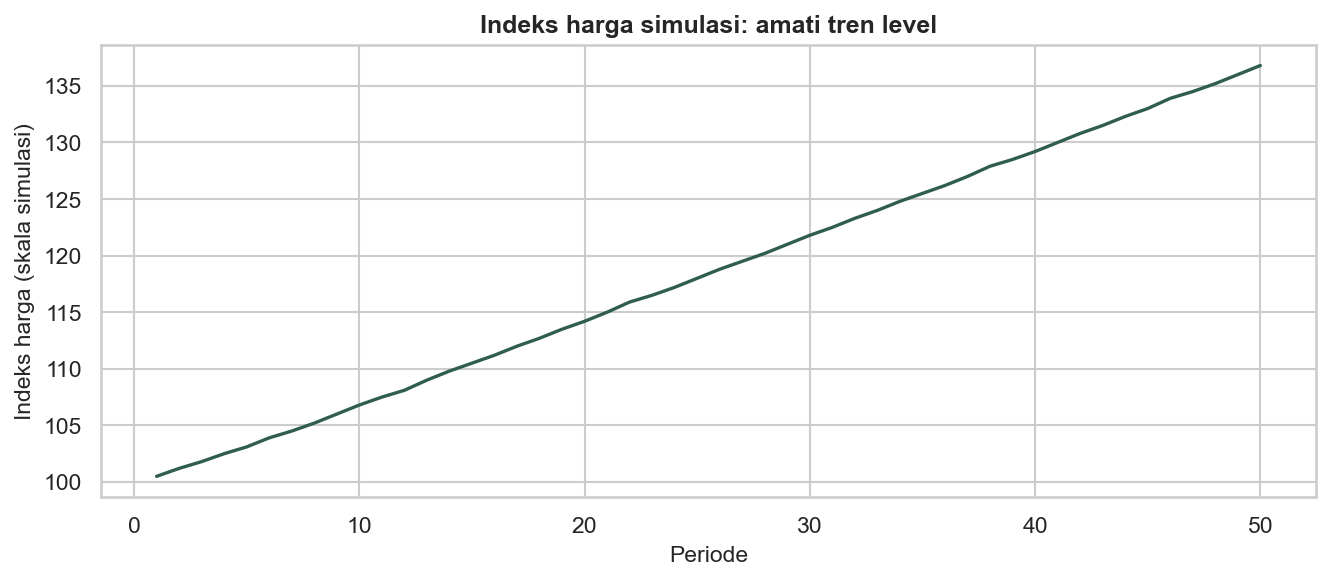

In [5]:
plt.figure(figsize=(9, 4))
plt.plot(inflasi["obs"], inflasi["inflasi"], lw=1.6)
plt.title("Indeks harga simulasi: amati tren level")
plt.xlabel("Periode")
plt.ylabel("Indeks harga (skala simulasi)")
plt.tight_layout()
plt.show()

**Baca grafik sebelum lanjut:** Baca waktu dari kiri ke kanan dan cocokkan satuan sumbu Y. Cari perubahan tingkat, tren, dan periode bergejolak sebelum menafsirkan hasil model.

In [6]:
from statsmodels.tsa.stattools import adfuller

p_level = adfuller(inflasi["inflasi"])[1]
p_diff = adfuller(inflasi["inflasi"].diff().dropna())[1]
print(f"ADF di level          : p = {p_level:.4f}")
print(f"ADF setelah selisih   : p = {p_diff:.4f}")


ADF di level          : p = 0.8192
ADF setelah selisih   : p = 0.0000


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_3556\124167482.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_level = adfuller(inflasi["inflasi"])[1]
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_3556\124167482.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_diff = adfuller(inflasi["inflasi"].diff().dropna())[1]


### Membaca hasil

Di level, p-value besar: data tidak stasioner (ada tren). Setelah satu
kali selisih, p-value kecil: sudah stasioner. Kesimpulan: pakai d = 1.

Model ARIMA(1,1,0) artinya: satu kali selisih, satu komponen AR.



In [7]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(inflasi["inflasi"], order=(1, 1, 0)).fit()
print(model.summary())


                               SARIMAX Results                                
Dep. Variable:                inflasi   No. Observations:                   50
Model:                 ARIMA(1, 1, 0)   Log Likelihood                  28.907
Date:                Sun, 25 Oct 2026   AIC                            -53.813
Time:                        17:37:46   BIC                            -50.030
Sample:                             0   HQIC                           -52.378
                                 - 50                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9850      0.025     38.966      0.000       0.935       1.035
sigma2         0.0168      0.004      4.494      0.000       0.009       0.024
Ljung-Box (L1) (Q):                  13.72   Jarque-

Ramalan inflasi 5 periode ke depan:
[137.59 138.36 139.13 139.88 140.62]


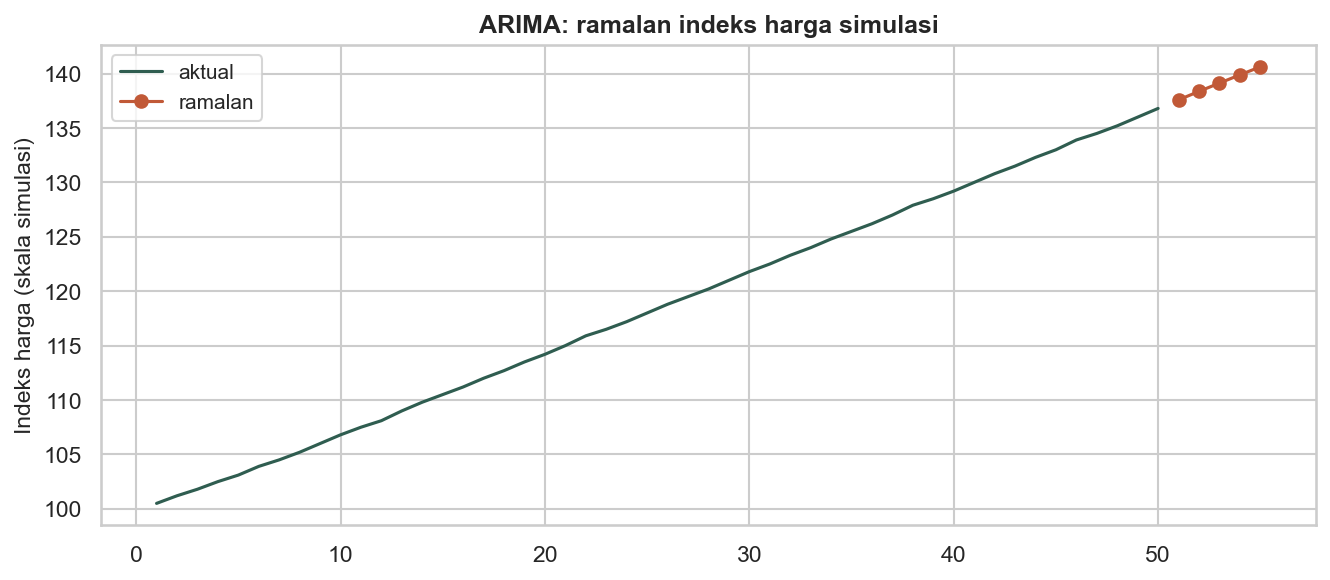

In [8]:
ramalan = model.get_forecast(steps=5)
print("Ramalan inflasi 5 periode ke depan:")
print(np.asarray(ramalan.predicted_mean).round(2))

plt.figure(figsize=(9, 4))
plt.plot(inflasi["obs"], inflasi["inflasi"], label="aktual")
masa_depan = np.arange(51, 56)
plt.plot(masa_depan, np.asarray(ramalan.predicted_mean), marker="o", label="ramalan")
plt.legend()
plt.title("ARIMA: ramalan indeks harga simulasi")
plt.ylabel("Indeks harga (skala simulasi)")
plt.tight_layout()
plt.show()


**Baca grafik sebelum lanjut:** Baca waktu dari kiri ke kanan dan cocokkan satuan sumbu Y. Cari perubahan tingkat, tren, dan periode bergejolak sebelum menafsirkan hasil model.

## 2. Kointegrasi dan ECM

Data `data/konsumsi_pendapatan.csv`. Dua variabel yang sama-sama
tidak stasioner bisa tetap berjalan bersama dalam jangka panjang.



<!-- kamus_variabel:konsumsi_pendapatan.csv -->

### Kenali data: Konsumsi dan pendapatan runtun waktu

**Data:** `data/konsumsi_pendapatan.csv`. **Satu baris:** satu tahun berurutan pada data simulasi.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun` | `Tahun` | Nomor tahun dalam urutan simulasi, bukan tahun kalender. | 1, 2, 3, ... | Penanda waktu |
| `Konsumsi_Y` | `konsumsi` | Nilai konsumsi pada periode tersebut. | Skala uang tidak dirinci | Y: target |
| `Pendapatan_X` | `pendapatan` | Nilai pendapatan pada periode yang sama. | Skala uang tidak dirinci | X: penjelas |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ln_konsumsi` | Logaritma alami nilai konsumsi. | Skala logaritma |
| `ln_pendapatan` | Logaritma alami nilai pendapatan. | Skala logaritma |
| `d_konsumsi` | Selisih log konsumsi dari periode sebelumnya. | Perubahan log, belum dikalikan 100 |
| `d_pendapatan` | Selisih log pendapatan dari periode sebelumnya. | Perubahan log, belum dikalikan 100 |
| `ect` | Error Correction Term: penyimpangan dari hubungan jangka panjang pada periode sebelumnya. | Residual log periode sebelumnya |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [9]:
from statsmodels.tsa.stattools import coint

makro = pd.read_csv(URL_DATA + "konsumsi_pendapatan.csv")
makro = makro.rename(columns={"Konsumsi_Y": "konsumsi", "Pendapatan_X": "pendapatan"})

makro.head()

,Tahun,konsumsi,pendapatan
0,1,100.5,120.2
1,2,102.1,122.5
2,3,104.3,125.1
3,4,103.8,124.8
4,5,106.5,128.4


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [10]:
makro["ln_konsumsi"] = np.log(makro["konsumsi"])
makro["ln_pendapatan"] = np.log(makro["pendapatan"])

print("ADF level:")
print("  ln(konsumsi)  :", round(adfuller(makro["ln_konsumsi"])[1], 4))
print("  ln(pendapatan):", round(adfuller(makro["ln_pendapatan"])[1], 4))

ADF level:
  ln(konsumsi)  : 0.0232
  ln(pendapatan): 0.0128


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_3556\3276321719.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("  ln(konsumsi)  :", round(adfuller(makro["ln_konsumsi"])[1], 4))
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_3556\3276321719.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("  ln(pendapatan):", round(adfuller(makro["ln_pendapatan"])[1], 4)

**Batas contoh simulasi ini.** ADF dengan konstanta pada log kedua seri
memberi p sekitar 0,023 dan 0,013: akar unit sudah ditolak pada level.
Jadi hasil coint di bawah tidak cukup untuk menyatakan kedua seri I(1)
terkointegrasi. Perhitungan berikut memperagakan bentuk persamaan jangka
panjang dan komponen ECM, bukan bukti empiris kointegrasi yang sah.
Untuk penelitian, tetapkan tren/konstanta berdasarkan teori dan grafik,
periksa orde integrasi, lalu gunakan uji kointegrasi yang sesuai.



In [11]:
p_kointe = coint(makro["ln_konsumsi"], makro["ln_pendapatan"])[1]
print(f"\nUji kointegrasi: p = {p_kointe:.4f}")
print("ECM berikut adalah demonstrasi; syarat I(1) belum terpenuhi pada contoh ini.")



Uji kointegrasi: p = 0.0001
ECM berikut adalah demonstrasi; syarat I(1) belum terpenuhi pada contoh ini.


In [12]:
sampel_model_lr = makro[["ln_konsumsi", "ln_pendapatan"]].dropna()
X_model_lr = sampel_model_lr[["ln_pendapatan"]]
y_model_lr = sampel_model_lr["ln_konsumsi"]

model_lr = LinearRegression()
model_lr.fit(X_model_lr, y_model_lr)

koefisien_model_lr = pd.Series(model_lr.coef_, index=X_model_lr.columns)
koefisien_model_lr.loc["Intercept"] = model_lr.intercept_

prediksi_model_lr = pd.Series(model_lr.predict(X_model_lr), index=y_model_lr.index)
residu_model_lr = y_model_lr - prediksi_model_lr
print("Persamaan jangka panjang:")
print(koefisien_model_lr.round(3))


Persamaan jangka panjang:
ln_pendapatan    0.875
Intercept        0.420
dtype: float64


### Lihat hasil model: Log konsumsi

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

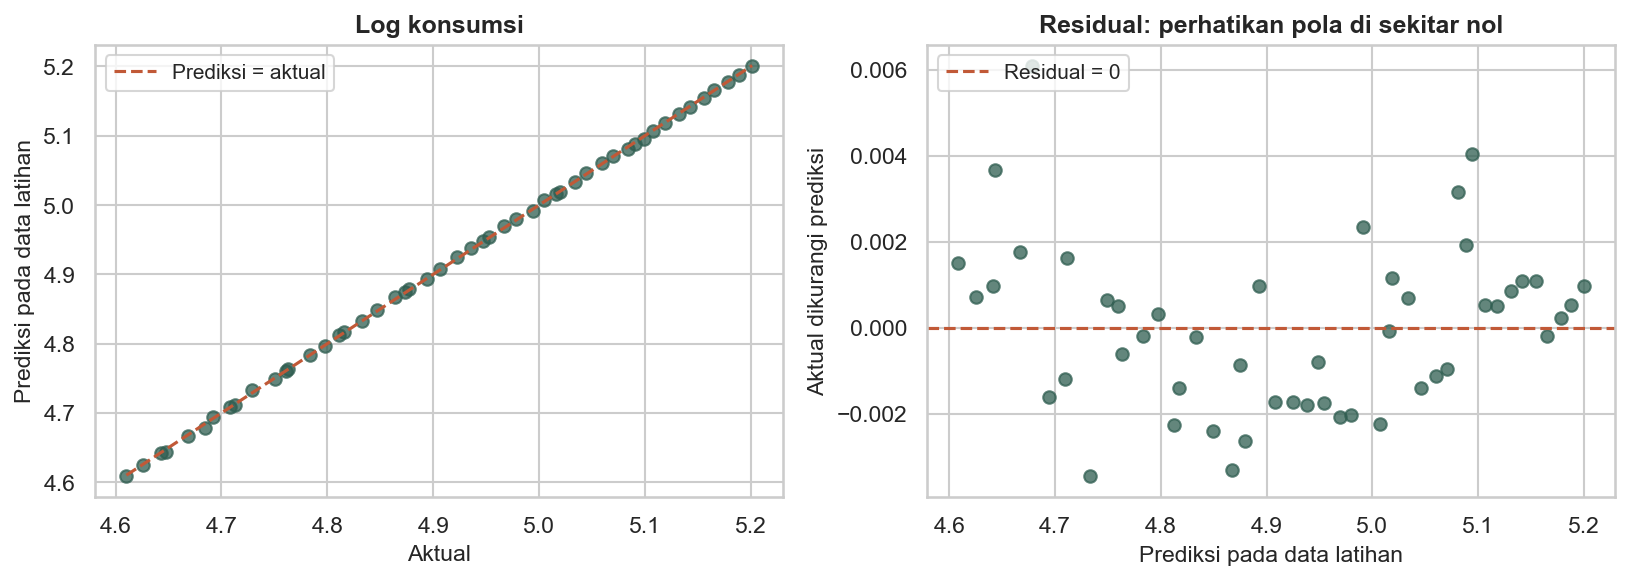

In [13]:
prediksi_visual = model_lr.predict(X_model_lr)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_lr, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_lr.min(), y_model_lr.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Log konsumsi")
axes[1].scatter(prediksi_visual, y_model_lr - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

In [14]:
# Siapkan komponen ECM: selisih untuk efek jangka pendek
makro["d_konsumsi"] = makro["ln_konsumsi"].diff()
makro["d_pendapatan"] = makro["ln_pendapatan"].diff()
# ECT = residual jangka panjang periode sebelumnya (koreksi ketidakseimbangan)
makro["ect"] = residu_model_lr.shift(1)

sampel_model_ecm = makro[["d_konsumsi", "d_pendapatan", "ect"]].dropna()
X_model_ecm = sampel_model_ecm[["d_pendapatan", "ect"]]
y_model_ecm = sampel_model_ecm["d_konsumsi"]

model_ecm = LinearRegression()
model_ecm.fit(X_model_ecm, y_model_ecm)

koefisien_model_ecm = pd.Series(model_ecm.coef_, index=X_model_ecm.columns)
koefisien_model_ecm.loc["Intercept"] = model_ecm.intercept_


### Lihat hasil model: Perubahan log konsumsi

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

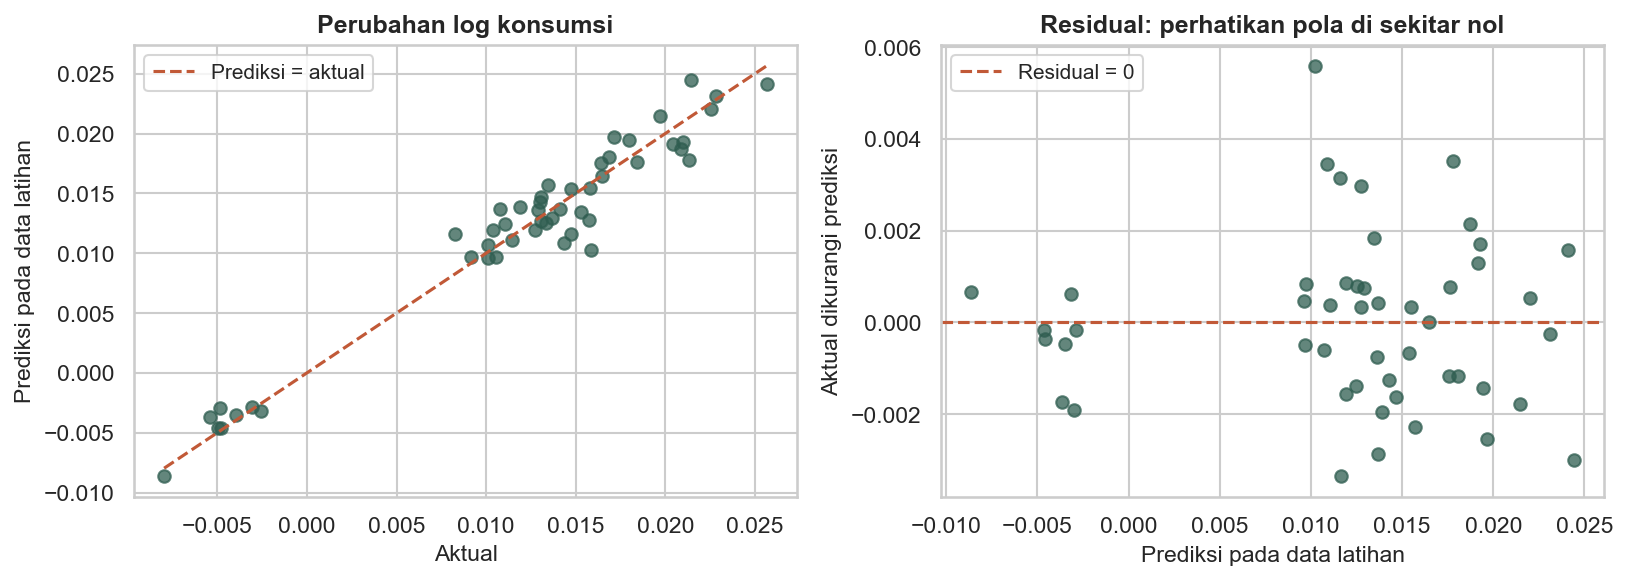

In [15]:
prediksi_visual = model_ecm.predict(X_model_ecm)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_ecm, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_ecm.min(), y_model_ecm.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Perubahan log konsumsi")
axes[1].scatter(prediksi_visual, y_model_ecm - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [16]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_ecm = sm.OLS(
    y_model_ecm,
    sm.add_constant(X_model_ecm, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print("\nECM:")
print(koefisien_model_ecm.round(3))
print(uji_model_ecm.pvalues.round(4))



ECM:
d_pendapatan    0.870
ect            -0.705
Intercept       0.000
dtype: float64
Intercept       0.9321
d_pendapatan    0.0000
ect             0.0000
dtype: float64


### Membaca hasil

Koefisien `ect` = -0,70 dan signifikan. Artinya 70 persen
ketidakseimbangan periode sebelumnya dikoreksi pada periode ini, menuju
keseimbangan jangka panjang.



## 3. Data panel

Data `data/panel_padi.csv`: 5 petak sawah x 10 musim. Hasil panen
dijelaskan pupuk dan curah hujan. Dengan struktur panel, kita bisa
memisahkan pengaruh yang melekat pada tiap petak.



<!-- kamus_variabel:panel_padi.csv -->

### Kenali data: Panel hasil panen padi

**Data:** `data/panel_padi.csv`. **Satu baris:** satu petak sawah pada satu musim tanam.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `FarmID` | Kode petak sawah yang diamati berulang. | Nomor identitas lahan | Penanda, bukan besaran ekonomi |
| `Season` | Urutan musim tanam. | Musim tanam ke-1, ke-2, ... | Penanda waktu |
| `Yield_Y` | Jumlah gabah yang dihasilkan oleh petak sawah. | Ton gabah; bukan otomatis ton per hektar | Y: target |
| `Fertilizer_X1` | Banyaknya pupuk yang digunakan. | Kilogram (kg) | X: penjelas |
| `Rainfall_X2` | Banyaknya curah hujan pada musim tanam. | Milimeter (mm) | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [17]:
from linearmodels.panel import PanelOLS

padi = pd.read_csv(URL_DATA + "panel_padi.csv")

padi.head()

,FarmID,Season,Yield_Y,Fertilizer_X1,Rainfall_X2
0,1,1,5.2,100,200
1,1,2,5.5,110,210
2,1,3,6.0,120,220
3,1,4,5.8,115,205
4,1,5,6.5,130,250


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [18]:
padi = padi.set_index(["FarmID", "Season"])
y = padi["Yield_Y"]
X = padi[["Fertilizer_X1", "Rainfall_X2"]]

fem = PanelOLS(y, X, entity_effects=True).fit(cov_type="clustered", cluster_entity=True)
print(fem.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                Yield_Y   R-squared:                        0.9964
Estimator:                   PanelOLS   R-squared (Between):              0.9930
No. Observations:                  50   R-squared (Within):               0.9964
Date:                Sun, Oct 25 2026   R-squared (Overall):              0.9930
Time:                        17:37:48   Log-likelihood                    86.131
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      5943.0
Entities:                           5   P-value                           0.0000
Avg Obs:                      10.0000   Distribution:                    F(2,43)
Min Obs:                      10.0000                                           
Max Obs:                      10.0000   F-statistic (robust):          8.293e+32
                            

### Lahan yang sama diamati pada beberapa musim

reset_index mengembalikan penanda lahan dan musim menjadi kolom sebelum digambar.

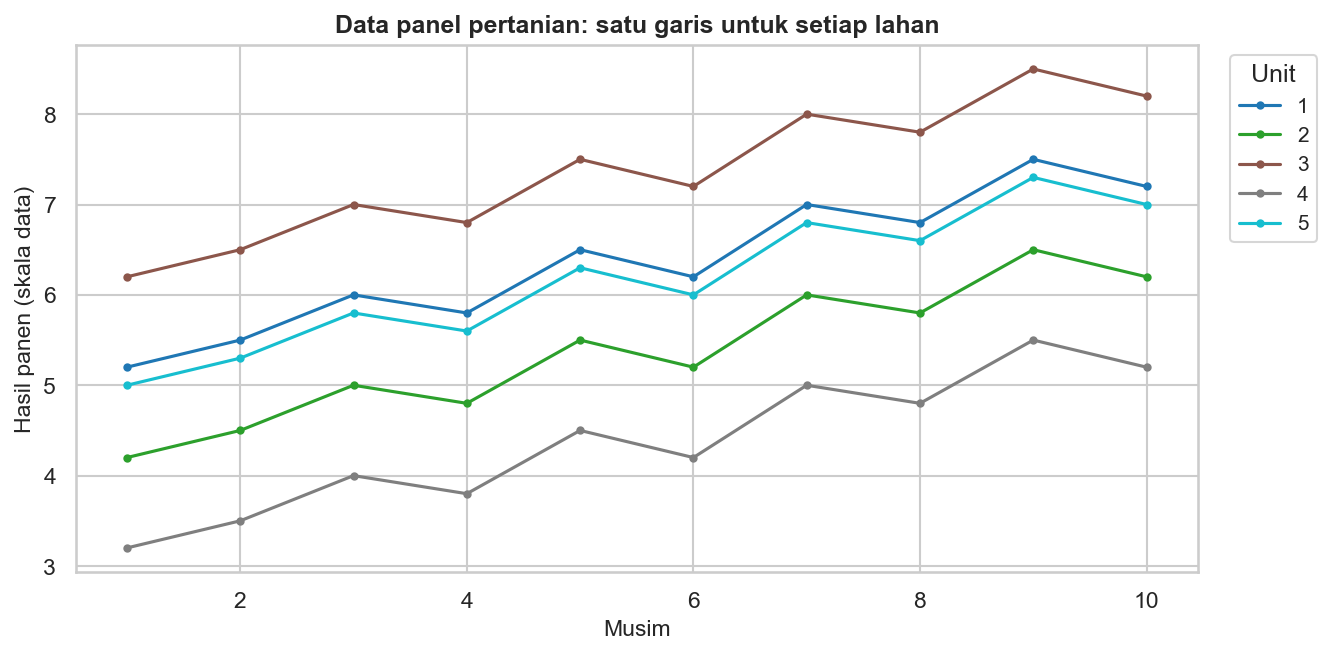

In [19]:
tabel_garis = padi.reset_index().pivot(index="Season", columns="FarmID", values="Yield_Y")
ax = tabel_garis.plot(colormap="tab10", figsize=(9, 4.5), marker="o", markersize=3)
ax.set_xlabel("Musim")
ax.set_ylabel("Hasil panen (skala data)")
ax.set_title("Data panel pertanian: satu garis untuk setiap lahan")
ax.legend(title="Unit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** Perhatikan apakah ada lahan yang konsisten lebih tinggi. Fixed effect mempertimbangkan ciri tetap tiap lahan; besarnya pengaruh pupuk dan hujan tetap dibaca dari model.

In [20]:
print("Uji Chow (pooled vs fixed effect):")
print(fem.f_pooled)


Uji Chow (pooled vs fixed effect):
Pooled F-statistic
H0: Effects are zero
Statistic: 12.6400
P-value: 0.0000
Distributed: F(4,43)


### Membaca hasil

p-value uji Chow sangat kecil: efek individu petak sawah nyata, jadi
Fixed Effect lebih tepat daripada mencampur semua petak. Koefisien
pupuk sekitar 0,038: tambahan satu kg pupuk per hektar menaikkan hasil
sekitar 0,038 ton per hektar dalam petak yang sama.



### Coba sendiri (5 menit)

Jalankan CEM (tanpa `entity_effects`) untuk data padi. Bandingkan
koefisien pupuknya dengan FEM di atas. Kenapa berbeda?

Tulis di sel di bawah, baru buka jawabannya.



In [21]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

CEM memberi koefisien pupuk 0,0507, FEM 0,0382. CEM mencampur
perbedaan antar petak sawah dengan perubahan dalam satu petak,
sehingga angkanya lebih besar. FEM lebih tepat untuk pertanyaan
perubahan dalam petak yang sama.

</details>



## 4. Latihan mandiri

**Latihan 1: ADF dan ARIMA untuk saham.** Data `data/ts_saham.csv`.
- Cek ADF di level dan setelah selisih. Stasioner di level atau setelah
  selisih?
- Estimasi ARIMA(1,1,0) dan ramalkan 5 periode.



<!-- kamus_variabel:ts_saham.csv -->

### Kenali data: Harga saham simulasi

**Data:** `data/ts_saham.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `saham` | Deret harga saham simulasi untuk uji stasioneritas dan peramalan. | Level harga; skala uang tidak dirinci | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [22]:
# saham_ts = pd.read_csv(URL_DATA + "ts_saham.csv")
# ...


**Latihan 2: kointegrasi IHSG dan emas.** Data `data/ihsg_emas.csv`.
- Jalankan uji `coint(IHSG_Y, Emas_X)`.
- Kalau p < 0,05, estimasi ECM. Kalau tidak, jelaskan kenapa ECM
  sebaiknya tidak dipakai.



<!-- kamus_variabel:ihsg_emas.csv -->

### Kenali data: IHSG dan harga emas simulasi

**Data:** `data/ihsg_emas.csv`. **Satu baris:** satu bulan berurutan pada contoh simulasi.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Bulan` | Urutan bulan pengamatan. | Nomor bulan; tanggal kalender tidak dicantumkan | Penanda waktu |
| `IHSG_Y` | Indeks Harga Saham Gabungan dalam contoh simulasi. | Poin indeks | Y: target |
| `Emas_X` | Harga emas pada contoh simulasi. | Mata uang dan berat acuan tidak dirinci | X: penjelas |

Tabel ini adalah contoh simulasi; berbeda dari data IHSG harian unduhan Yahoo Finance.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [23]:
# ie = pd.read_csv(URL_DATA + "ihsg_emas.csv")
# ...


**Latihan 3: panel retail.** Data `data/panel_retail.csv`
(5 toko x 10 bulan, `Sales_Y ~ Ads_X1 + Discount_X2`).
- Estimasi CEM (tanpa `entity_effects`) dan FEM (dengan
  `entity_effects=True`).
- Bandingkan koefisien diskon di kedua model. Mana yang Anda percaya
  untuk kebijakan diskon? Kenapa?



<!-- kamus_variabel:panel_retail.csv -->

### Kenali data: Panel toko ritel

**Data:** `data/panel_retail.csv`. **Satu baris:** satu cabang toko pada satu bulan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `StoreID` | Kode cabang toko. | Nomor identitas toko | Penanda, bukan besaran ekonomi |
| `Month` | Urutan bulan dalam panel. | Bulan ke-1, ke-2, ... | Penanda waktu |
| `Sales_Y` | Besarnya penjualan toko pada bulan tersebut. | Satuan/skala tidak dirinci sumber | Y: target |
| `Ads_X1` | Biaya iklan cabang toko. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Discount_X2` | Proporsi potongan harga. | Pecahan; 0,10 berarti diskon 10% | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [24]:
# retail = pd.read_csv(URL_DATA + "panel_retail.csv").set_index(["StoreID", "Month"])
# ...


### Selanjutnya

Selanjutnya: Lab 6, data Indonesia asli.
